In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("C:\\Users\\User\\Downloads\\heart+disease\\heart_disease_combined_raw(3).csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (900, 77)

First 5 rows:


,source,id,ccf,age,sex,painloc,painexer,relrest,pncaden,cp,...,rcaprox,rcadist,lvx1,lvx2,lvx3,lvx4,lvf,cathef,junk,name
0,Cleveland,1,0,63,1,-9,-9,-9,-9,1,...,1,1,1,1,1,1,1,-9.0,-9.0,name
1,Cleveland,2,0,67,1,-9,-9,-9,-9,4,...,1,1,1,1,1,1,1,-9.0,-9.0,name
2,Cleveland,3,0,67,1,-9,-9,-9,-9,4,...,2,2,1,1,1,7,3,-9.0,-9.0,name
3,Cleveland,4,0,37,1,-9,-9,-9,-9,3,...,1,1,1,1,1,1,1,-9.0,-9.0,name
4,Cleveland,6,0,41,0,-9,-9,-9,-9,2,...,1,1,1,1,1,1,1,-9.0,-9.0,name


In [4]:
# Convert original target into binary target
# 0 = No Heart Disease
# 1 = Heart Disease Present

df_model = df.copy()

df_model["target"] = (df_model["num"] > 0).astype(int)

features = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
]

X = df_model[features].copy()
y = df_model["target"].copy()

print("Number of features:", X.shape[1])
print("Number of records:", X.shape[0])

print("\nTarget Distribution:")
print(y.value_counts())

Number of features: 13
Number of records: 900

Target Distribution:
target
1    496
0    404
Name: count, dtype: int64


In [6]:
# Convert possible missing-value representations to NaN
X = X.replace(["?", "NA", "N/A"], np.nan)

# Convert columns to numeric where possible
for column in X.columns:
    X[column] = pd.to_numeric(X[column], errors="coerce")

print("Missing values before imputation:")
print(X.isnull().sum())

# Median imputation
for column in X.columns:
    X[column] = X[column].fillna(X[column].median())

print("\nMissing values after imputation:")
print(X.isnull().sum().sum())

Missing values before imputation:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64

Missing values after imputation:
0


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 720
Testing samples: 180

Training class distribution:
target
1    397
0    323
Name: count, dtype: int64

Testing class distribution:
target
1    99
0    81
Name: count, dtype: int64


In [8]:
# Logistic Regression
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# KNN
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

# SVM
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

# Decision Tree
decision_tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42
)

# Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "SVM": svm_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

print("Models defined successfully.")

Models defined successfully.


In [9]:
results = []
trained_models = {}

for name, model in models.items():

    # Train only on training data
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Probability scores for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

    trained_models[name] = model

comparison_df = pd.DataFrame(results)

print("Model evaluation completed.")
display(comparison_df.round(4))

Model evaluation completed.


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8000,0.8058,0.8384,0.8218,0.8677
1,KNN,0.8333,0.8286,0.8788,0.8529,0.8897
2,SVM,0.8278,0.8148,0.8889,0.8502,0.9108
3,Decision Tree,0.7889,0.7850,0.8485,0.8155,0.8509
4,Random Forest,0.8500,0.8273,0.9192,0.8708,0.9135


In [10]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Mean Accuracy": scores.mean(),
        "CV Std": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

print("5-Fold Cross-Validation Results:")
display(cv_df.round(4))

5-Fold Cross-Validation Results:


,Model,CV Mean Accuracy,CV Std
0,Logistic Regression,0.8069,0.0302
1,KNN,0.7764,0.0327
2,SVM,0.7972,0.0250
3,Decision Tree,0.7667,0.0303
4,Random Forest,0.8097,0.0168


In [11]:
parameter_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

tuning_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=parameter_grid,
    n_iter=8,
    scoring="accuracy",
    cv=tuning_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

tuned_rf = rf_search.best_estimator_

print("\nBest Parameters:")
print(rf_search.best_params_)

print("\nBest CV Accuracy:")
print(rf_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best Parameters:
{'n_estimators': 50, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}

Best CV Accuracy:
0.8250000000000001


In [12]:
y_pred_tuned = tuned_rf.predict(X_test)
y_prob_tuned = tuned_rf.predict_proba(X_test)[:, 1]

tuned_results = {
    "Model": "Tuned Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, y_prob_tuned
    )
}

comparison_df = pd.concat(
    [
        comparison_df,
        pd.DataFrame([tuned_results])
    ],
    ignore_index=True
)

trained_models["Tuned Random Forest"] = tuned_rf

print("Final Model Comparison:")
display(comparison_df.round(4))

Final Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8000,0.8058,0.8384,0.8218,0.8677
1,KNN,0.8333,0.8286,0.8788,0.8529,0.8897
2,SVM,0.8278,0.8148,0.8889,0.8502,0.9108
3,Decision Tree,0.7889,0.7850,0.8485,0.8155,0.8509
4,Random Forest,0.8500,0.8273,0.9192,0.8708,0.9135
5,Tuned Random Forest,0.8389,0.8182,0.9091,0.8612,0.9075


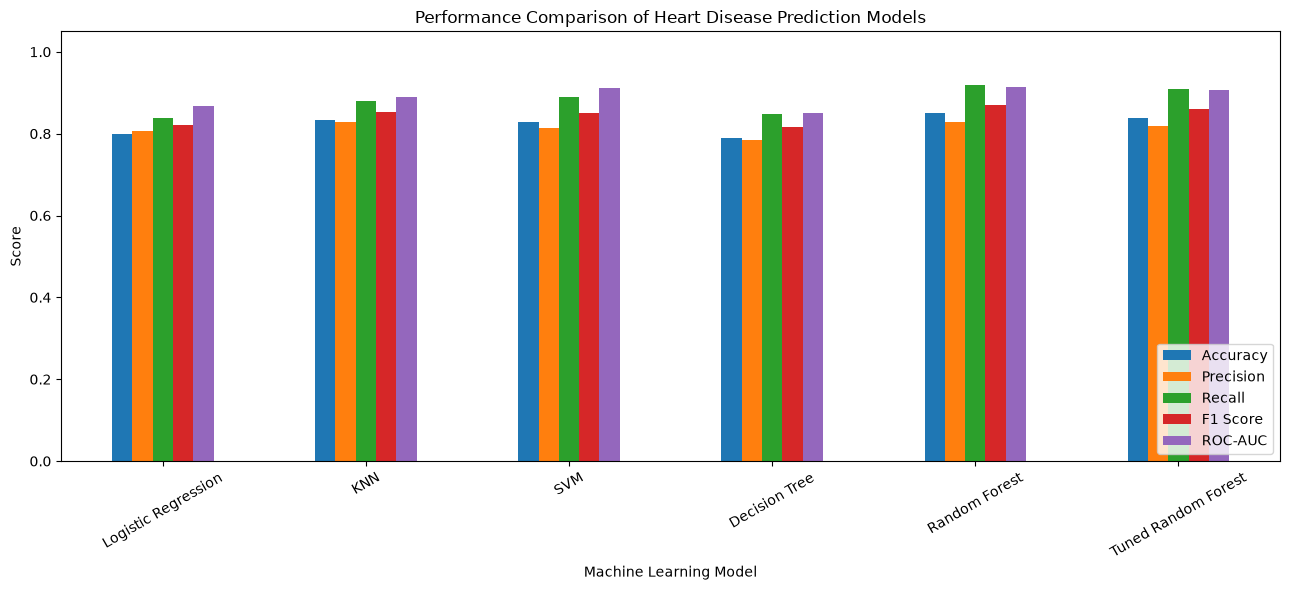

In [13]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Performance Comparison of Heart Disease Prediction Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

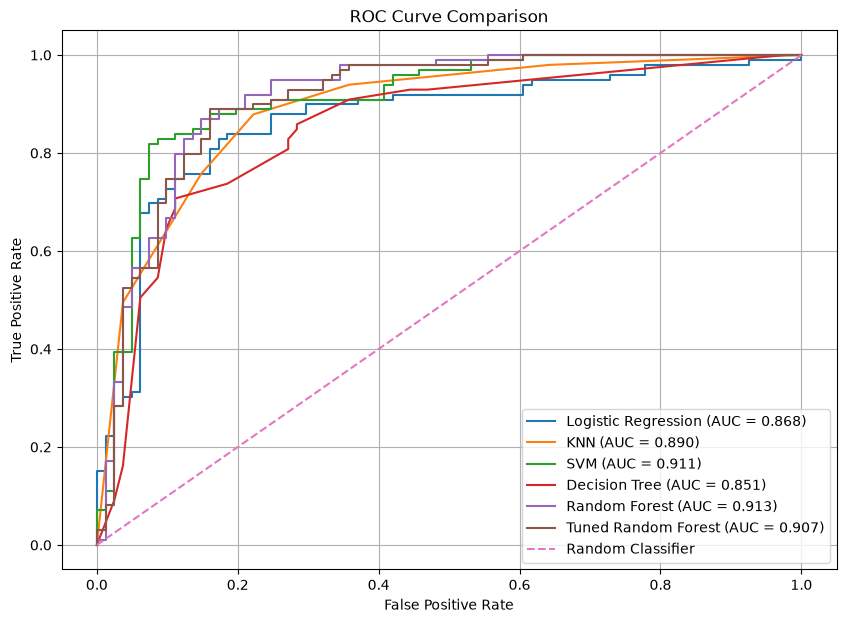

In [14]:
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

BEST-PERFORMING MODEL
Model: Random Forest
F1 Score: 0.8708
Accuracy: 0.85
Precision: 0.8273
Recall: 0.9192
ROC-AUC: 0.9135

Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.89      0.77      0.82        81
   Heart Disease       0.83      0.92      0.87        99

        accuracy                           0.85       180
       macro avg       0.86      0.84      0.85       180
    weighted avg       0.85      0.85      0.85       180



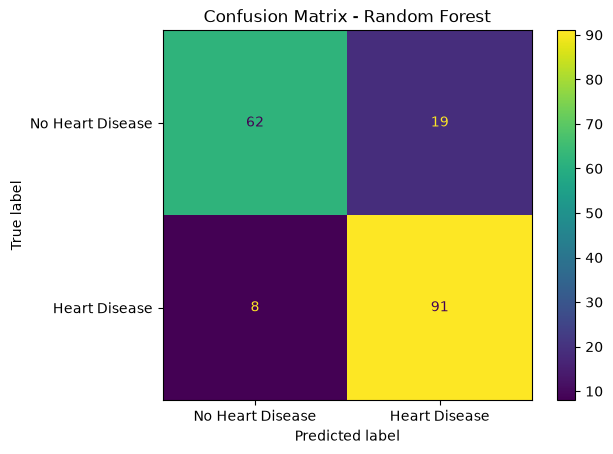

In [15]:
# Select model based on highest F1-score
best_index = comparison_df["F1 Score"].idxmax()

best_model_name = comparison_df.loc[
    best_index, "Model"
]

best_model = trained_models[best_model_name]

print("=" * 60)
print("BEST-PERFORMING MODEL")
print("=" * 60)

print("Model:", best_model_name)
print(
    "F1 Score:",
    round(comparison_df.loc[best_index, "F1 Score"], 4)
)

print(
    "Accuracy:",
    round(comparison_df.loc[best_index, "Accuracy"], 4)
)

print(
    "Precision:",
    round(comparison_df.loc[best_index, "Precision"], 4)
)

print(
    "Recall:",
    round(comparison_df.loc[best_index, "Recall"], 4)
)

print(
    "ROC-AUC:",
    round(comparison_df.loc[best_index, "ROC-AUC"], 4)
)

# Predictions from best model
best_predictions = best_model.predict(X_test)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        target_names=[
            "No Heart Disease",
            "Heart Disease"
        ],
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(y_test, best_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Heart Disease",
        "Heart Disease"
    ]
)

disp.plot()
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

In [16]:
# Save comparison results
comparison_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

# Save the selected model name
with open("best_model_name.txt", "w") as file:
    file.write(best_model_name)

# Save the trained best model
import joblib

joblib.dump(
    best_model,
    "final_heart_disease_model.pkl"
)

print("Files saved successfully:")
print("1. model_comparison_results.csv")
print("2. best_model_name.txt")
print("3. final_heart_disease_model.pkl")

print("\nSelected final model:", best_model_name)

Files saved successfully:
1. model_comparison_results.csv
2. best_model_name.txt
3. final_heart_disease_model.pkl

Selected final model: Random Forest
